# Bohrpfahl: Elementweise Berechnung

In [1]:
using Revise
using LinearAlgebra
import CairoMakie

using MMJMesh
using MMJMesh.Plots
using MMJMesh.Meshes
using MMJMesh.Mathematics

## Einführung

In diesem Abschnitt wird das lineare Gleichungssystem aus den Beiträgen der Elemente zusammengebaut (assembliert). Schritte:

1. Mit Basisfunktionen (wie im vorherigen Abschnitt) als Referenz

1. Mit Elementsteifigkeitsmatrizen

1. Mit FE-Netz

1. Mit wiederverwendbaren Funktionen

In jedem Schritt wird der Ablauf der Rechnung weiter verallgemeinert.

## Systemparameter

In [2]:
# Basiswerte
E = 35e9
d = 0.8
l = 20
F = 2e6
ρ = 2500
g = 9.81
S = 120e6
c = 1.75e7

# Abgeleitete Werte
C = c * π * d
A = π * d^2 / 4
EA = E * A
n = ρ * g * A;

## Schritt 1: Mit Basisfunktionen $\varphi_i: \Omega \to \mathbb{R}$ (wie gehabt)

Variationsformulierung

In [3]:
a(u, δu) = integrate(EA * u' * δu' + C * u * δu, 0 .. l) + S * u(l) * δu(l)
b(δu) = integrate(n * δu, 0 .. l) + F * δu(0)

b (generic function with 1 method)

Lösung für vier Elemente

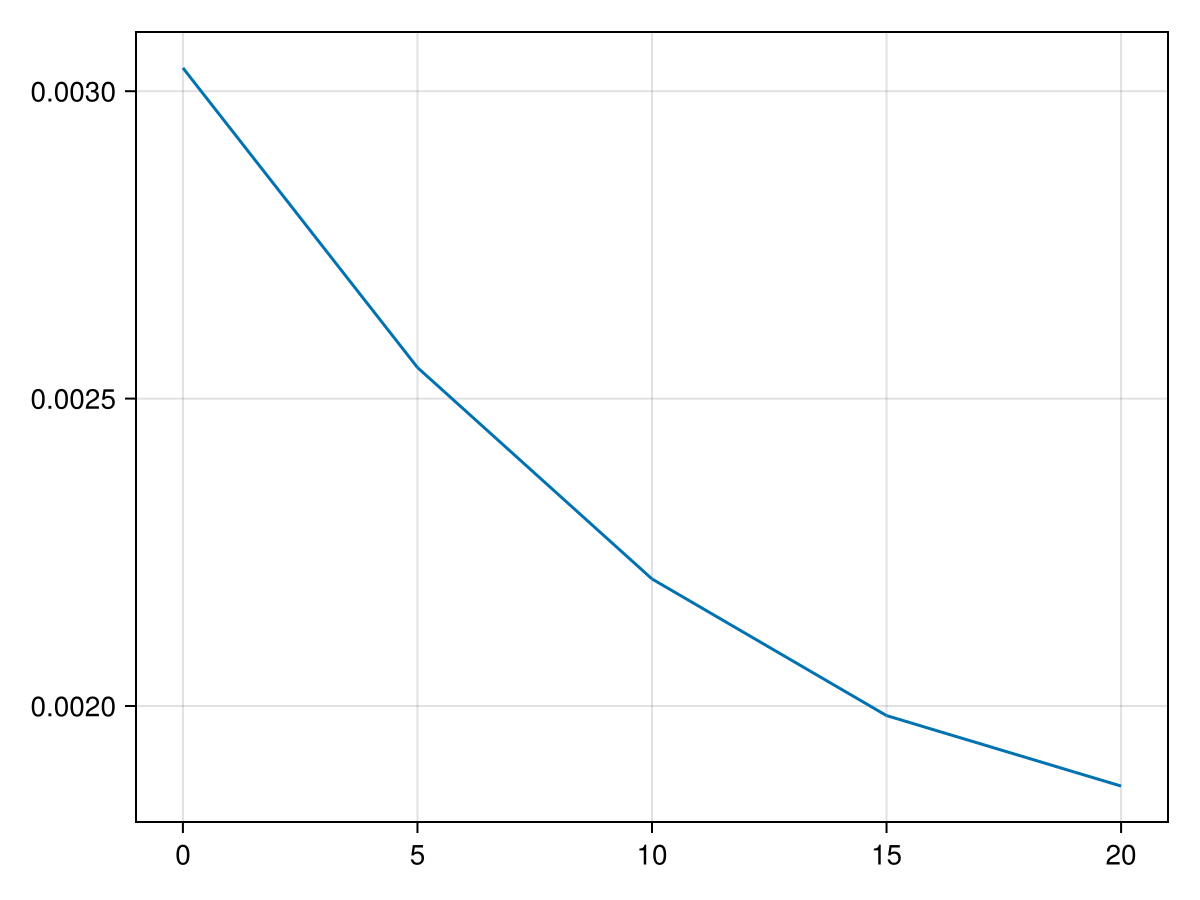

In [4]:
Ne = 4
phis = hatfunctions(range(0, l, Ne + 1))
K = [a(phii, phij) for phii = phis, phij = phis]
r = [b(phii) for phii = phis]
uHatGlobal = K \ r

fplot(uHatGlobal ⋅ phis)

## Schritt 2: Mit Elementsteifigkeitsmatrizen

### Vorbereitung

Addition von Untermatrix mit Indexvektor

In [ ]:
K = reshape(collect(1:16), 4, 4)
Ke = [100 200; 300 400]
Ie = [4, 1]
K[Ie, Ie] += Ke

display(K)

4×4 Matrix{Int64}:
 401  5   9  313
   2  6  10   14
   3  7  11   15
 204  8  12  116

Mit Assemblierungsmatrix

In [6]:
K = reshape(collect(1:16), 4, 4)
Ke = [100 200; 300 400]
Ae = [
    0 0 0 1
    1 0 0 0
]
K += Ae' * Ke * Ae

display(K)

4×4 Matrix{Int64}:
 401  5   9  313
   2  6  10   14
   3  7  11   15
 204  8  12  116

### Berechnung

Uniformes Netz mit Elementen der Länge $h$. Daher können wir $\mathbf{K}^e$ und $\mathbf{r}^e$ vorab berechnen.

[-1.734723475976807e-18, -2.168404344971009e-18, -1.734723475976807e-18, -1.3010426069826053e-18, -1.3010426069826053e-18]


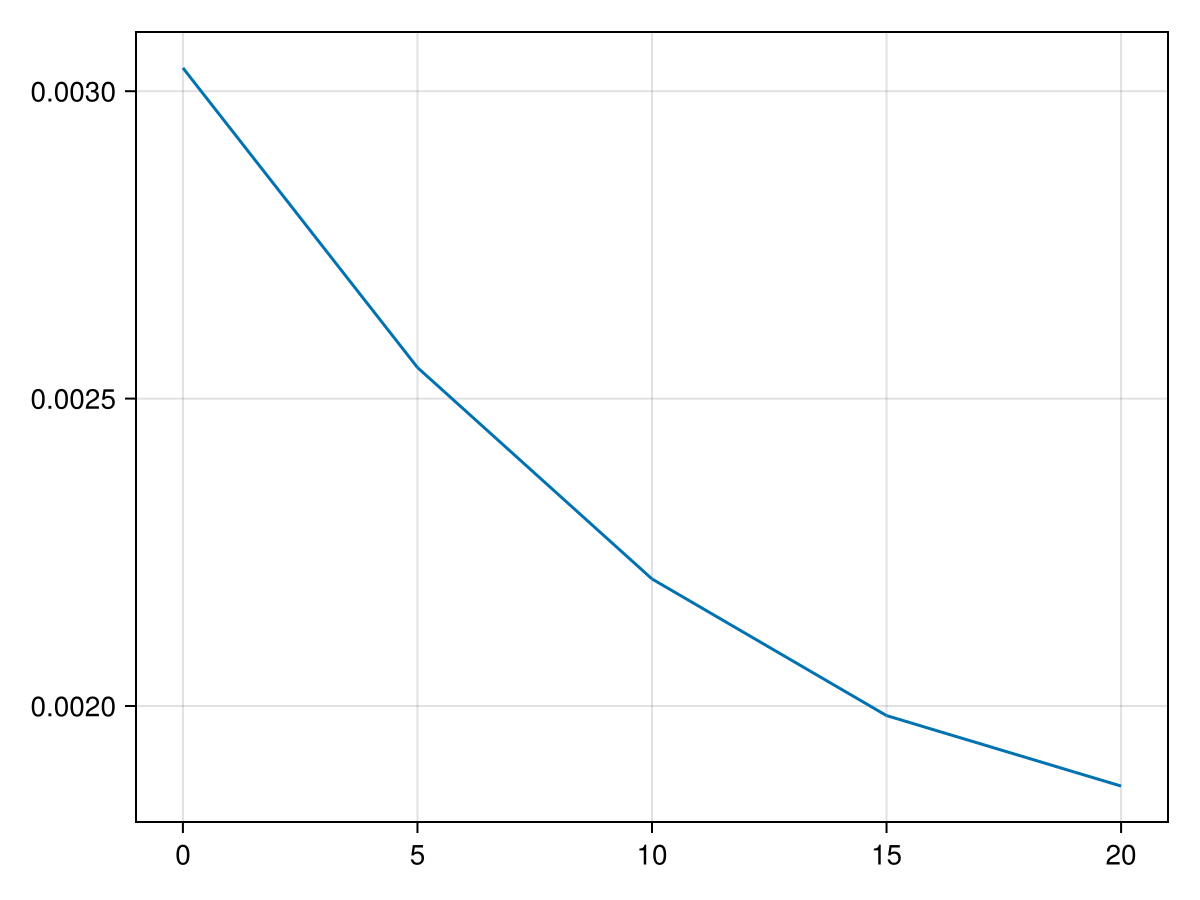

In [7]:
# Netz
Ne = 4
N = Ne + 1
h = l / Ne

# Element
Ke = EA / h * [1 -1; -1 1] + C * h / 6 * [2 1; 1 2]
re = n * h / 2 * [1, 1]

# System
K = zeros(N, N)
r = zeros(N)

# Schleife über alle Elemente
for e = 1:Ne
    Ie = [e, e + 1]
    K[Ie, Ie] += Ke
    r[Ie] += re
end

# Einzellast und Feder
r[1] += F
K[end, end] += S

# Näherungslösung
uHat = K \ r
uh = uHat ⋅ phis

# Kontrolle und Plot
println(uHatGlobal - uHat)
fplot(uh)

Bewertung:

- Ergebnisse sind gleich (bis auf Rundungsfehler)
- Funktioniert nur für uniforme Netze
- Code nicht wiederverwendbar

## Schritt 3: Mit FE-Netz

### Vorbereitung

#### FE-Netz

Netz aus MMJMesh

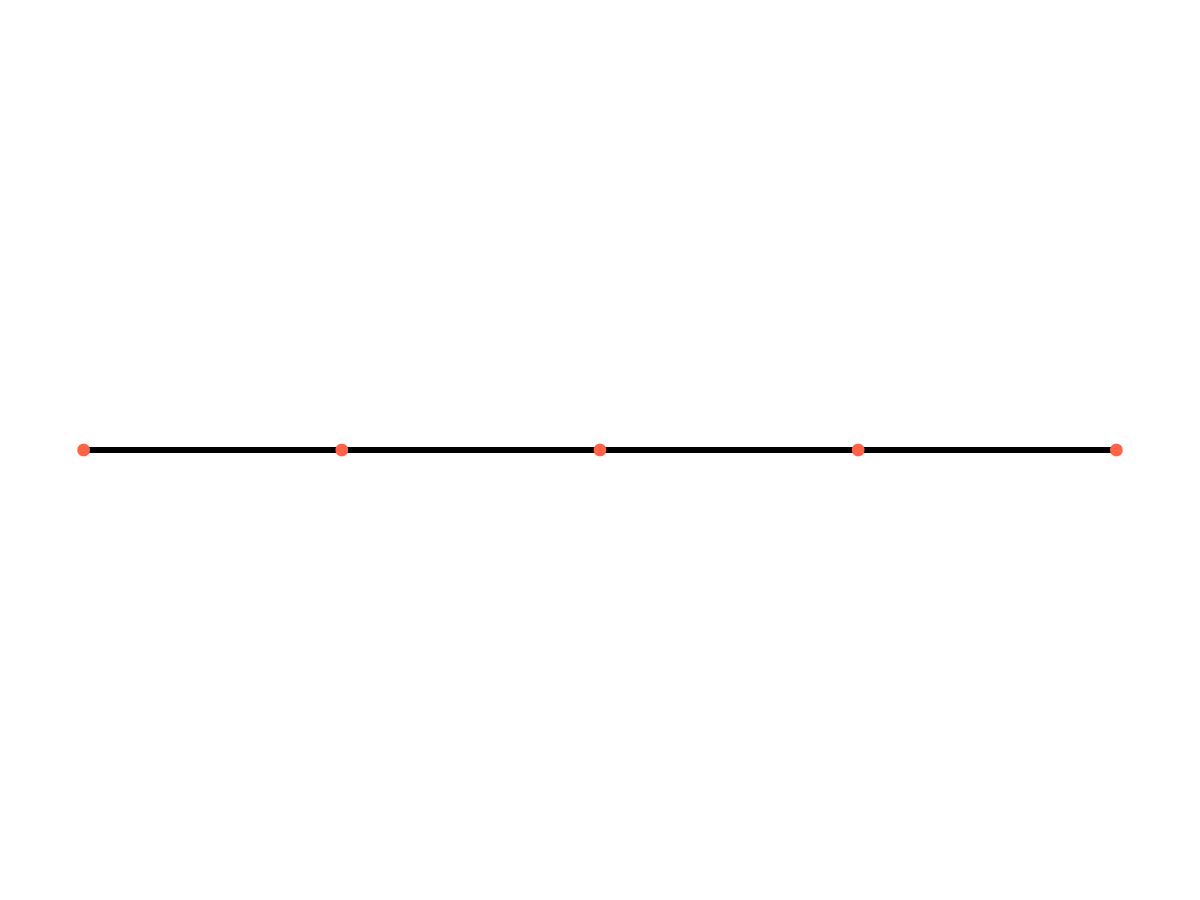

In [8]:
m = Mesh(0 .. l, Ne)
mplot(m) |> mconf()

Schleife über alle Netzobjekte (Knoten und Kanten/Elemente)

In [9]:
for e = entities(m)
    println(e)               # Netzobjekt
    println(nodeindices(e))  # Knotennummern
end

Node(1)[0.0, 0.0]
[1]
Node(2)[5.0, 0.0]
[2]
Node(3)[10.0, 0.0]
[3]
Node(4)[15.0, 0.0]
[4]
Node(5)[20.0, 0.0]
[5]
Edge(1)[1, 2]
[1, 2]
Edge(2)[2, 3]
[2, 3]
Edge(3)[3, 4]
[3, 4]
Edge(4)[4, 5]
[4, 5]


Ein Element

In [10]:
e3 = element(m, 3)           # Element heraussuchen
length(e3)                   # Länge berechnen

5.0

Eigenschaften für alle Elemente definieren

In [11]:
setdata!(group(m, :elements), :test, 99)
data(element(m, 3), :test)

99

Prüfen, ob Eigenschaft definiert

In [12]:
e2 = element(m, 2)
println(hasdata(e2, :test))
println(hasdata(e2, :hallo))

true
false


#### Funktionen sind Objekte erster Klasse

Siehe zum Beispiel den Artikel auf [Wikipedia](https://en.wikipedia.org/wiki/First-class_function)

Funktionen können Variablen zugewiesen werden

In [16]:
f = sin
f(π / 4)

0.7071067811865475

Und damit auch mit Netzobjekten assoziiert werden

In [17]:
setdata!(group(m, :elements), :do_it, f)
e4 = element(m, 4)
ef = data(e4, :do_it)
ef(π / 4)

0.7071067811865475

### Berechnung

Idee: Wir definieren Funktionen, die für Elemente und Knoten die Beiträge zur globalen Steifigkeitsmatrix (Elementsteifigkeitsmatrizen und Feder) und dem globalen Lastvektor (Elementlastvektoren und Einzellast) berechnen. Diese Funktionen hängen wir an Knoten und Elemente.

Funktionen

In [ ]:
function kefunc_pile(e)
    h = length(e)
    return EA / h * [1 -1; -1 1] + C * h / 6 * [2 1; 1 2]
end

function refunc_pile(e)
    h = length(e)
    return n * h / 2 * [1, 1]
end

function kefunc_spring(n)
    return [S;;]
end

function refunc_force(n)
    return [F]
end

e2 = element(m, 2)
n3 = node(m, 3)
println("K2 = ", kefunc_pile(e2))
println("r2 = ", refunc_pile(e2))
println("S = ", kefunc_spring(n3))
println("F = ", refunc_force(n3))


K2 = [3.5918876006043305e9 -3.481931857728688e9; -3.481931857728688e9 3.5918876006043305e9]
r2 = [30819.023931715874, 30819.023931715874]
S = [1.2e8;;]
F = [2.0e6]


Näherungslösung

[-1.734723475976807e-18, -2.168404344971009e-18, -1.734723475976807e-18, -1.3010426069826053e-18, -1.3010426069826053e-18]


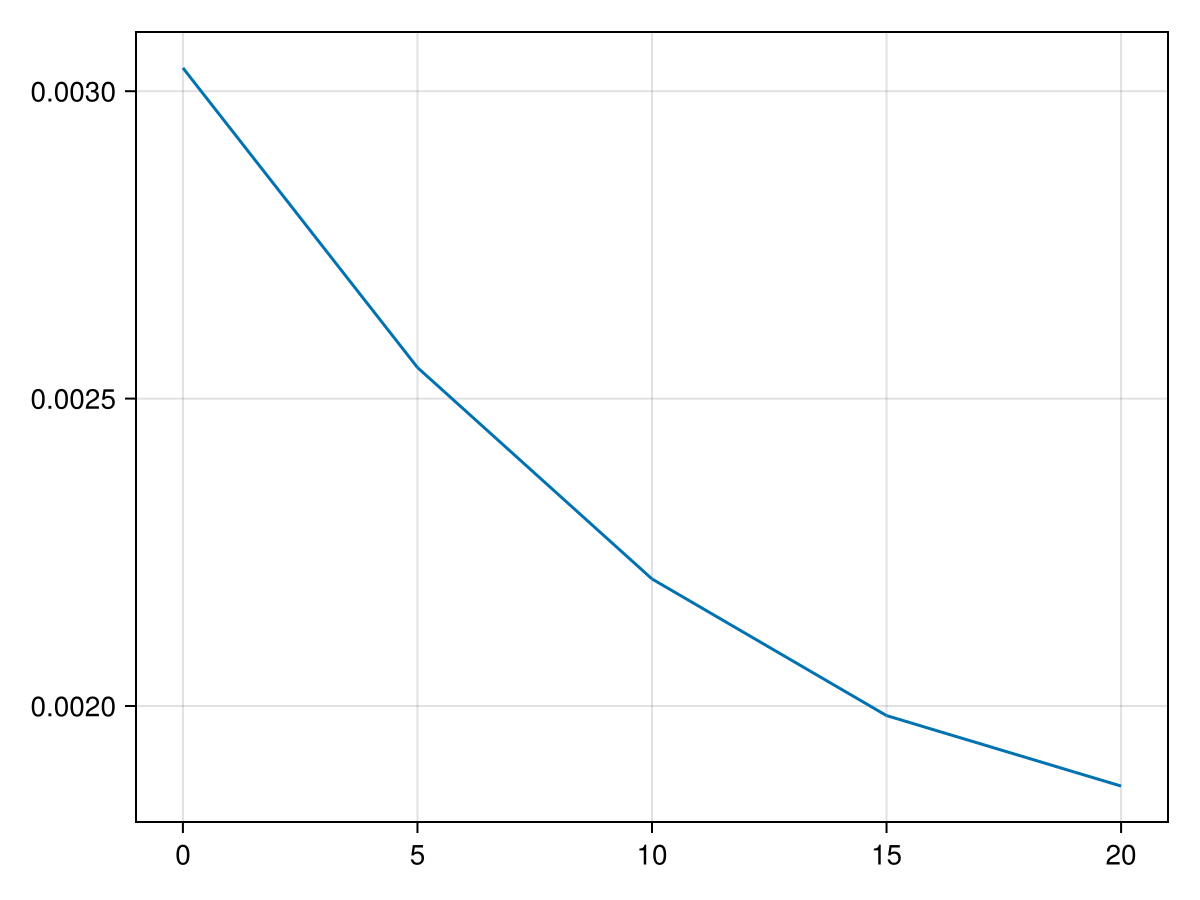

In [51]:
Ne = 4
N = Ne + 1
m = Mesh(0 .. l, Ne)

# Funktionen definieren
setdata!(group(m, :elements), :kefunc, kefunc_pile)
setdata!(group(m, :elements), :refunc, refunc_pile)
setdata!(node(m, N), :kefunc, kefunc_spring)
setdata!(node(m, 1), :refunc, refunc_force)

# Mit Nullen vorbelegen
K = zeros(N, N)
r = zeros(N)

# Schleife über alle Netzobjekte
for e = entities(m)
    Ie = nodeindices(e)

    if hasdata(e, :kefunc)
        kefunc = data(e, :kefunc)
        Ke = kefunc(e)
        K[Ie, Ie] += Ke
    end
    if hasdata(e, :refunc)
        refunc = data(e, :refunc)
        re = refunc(e)
        r[Ie] += re
    end
end

# Näherungslösung
uHat = K \ r
uh = uHat ⋅ phis

# Kontrolle und Plot
println(uHatGlobal - uHat)
fplot(uh)

Bewertung:

- Ergebnis wieder gleich (klar)
- Die Assemblierung des LGS weiß nichts über das konkrete Problem
- Aber: Weder die Funktionen für Netzobjekte noch die Assemblierung des LGS sind wiederverwendbar

## Schritt 4: Mit wiederverwendbaren Funktionen

### Vorbereitung

#### Parametrisierte Funktionen

In der Mathematik ist eine Funktionenfolge eine Vorschrift, die einer natürlichen Zahl eine Funktion zuweist, zum Beispiel

$$
    f_k(x) = \cos(k x)
$$

Umsetzung in Julia: Funktion, die eine Funktion zurückgibt, sozusagen eine parametrisierte Funktion

In [ ]:
function cosk(k)
    function f(x)
        return cos(k * x)
    end
    return f
end

p = CairoMakie.lines(0 .. 2π, cos)
for k = 2:4
    CairoMakie.lines!(0 .. 2π, cosk(k))
end
p

### Näherungslösung

Funktionen im Anhang

In [ ]:
includet("src/pile.jl")
includet("src/fem.jl")

# Problem definieren
Ne = 4
N = Ne + 1
m = Mesh(0 .. l, Ne)
setdata!(group(m, :elements), :kefunc, pile_ke(EA, C))
setdata!(group(m, :elements), :refunc, pile_re(n))
setdata!(node(m, N), :kefunc, spring(S))
setdata!(node(m, 1), :refunc, force(F))

# Berechnung
K, r = assemble_kr(m)
uHat = K \ r

# Kontrolle und Plot
println(uHatGlobal - uHat)
mplot(m, uHat)

Bewertung:

- Alles in Funktionen, die beliebig wiederverwendet werden können
    - Speziell: Problemformulierung Bohrpfahl
    - Allgemein: Gleichungssystem assemblieren